In [1]:
%pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from neo4j import GraphDatabase

# Konfigurasi Koneksi Neo4j Desktop
URI = "bolt://localhost:7687"
USER = "neo4j"
PASSWORD = "12345678"  

# Inisialisasi Driver
driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))

# Tes Koneksi
try:
    driver.verify_connectivity()
    print("✅ Berhasil terhubung ke Neo4j!")
except Exception as e:
    print(f"❌ Gagal konek: {e}")

✅ Berhasil terhubung ke Neo4j!


In [ ]:
def evaluate_model(method_name, community_filter=""):
    """
    Fungsi perbaikan evaluasi RMSE, MAE, dan Precision@10
    """
    query = f"""
    MATCH (u:User)-[test:RATED_TEST]->(rec:Movie)
    MATCH (u)-[r:RATED]->(m:Movie)
    WHERE r.rating >= 4.0
    MATCH (m)-[s:SIMILAR_COS]-(rec)
    {community_filter}
    WITH u, rec, test.rating AS aktual_rating,
         sum(s.weight * r.rating) / sum(s.weight) AS prediksi_rating
    WHERE prediksi_rating IS NOT NULL
    
    // Urutkan item berdasarkan prediksi rating tertinggi (Top-10 kandidat)
    WITH u, rec, aktual_rating, prediksi_rating,
         abs(prediksi_rating - aktual_rating) AS error_abs,
         (prediksi_rating - aktual_rating)^2 AS error_sq
    ORDER BY prediksi_rating DESC
    
    WITH u, 
         collect(aktual_rating)[0..10] AS top10_aktual,
         avg(error_abs) AS mae_user,
         avg(error_sq) AS mse_user
    
    // Hitung berapa banyak item di Top-10 yang benar-benar disukai (rating >= 4.0)
    WITH u, mae_user, mse_user,
         [r IN top10_aktual WHERE r >= 4.0] AS item_relevan,
         size(top10_aktual) AS total_top10
    
    RETURN '{method_name}' AS Metode,
           count(DISTINCT u) AS Total_User,
           round(avg(sqrt(mse_user)), 4) AS RMSE,
           round(avg(mae_user), 4) AS MAE,
           round(avg(toFloat(size(item_relevan)) / total_top10), 4) AS Precision_At_10
    """
    with driver.session() as session:
        result = session.run(query)
        return result.single().data()

print("⏳ Sedang mengevaluasi ketiga metode di Neo4j...")

#Item-Based CF Murni
res_cf = evaluate_model("CF Murni", "")

#CF + Leiden (Amaa)
res_leiden = evaluate_model("CF + Leiden", "WHERE rec.leidenId = m.leidenId")

#CF + Louvain (Mufti)
res_louvain = evaluate_model("CF + Louvain", "WHERE rec.louvainId = m.louvainId")

#Tampilkan Tabel DataFrame Pandas
df_eval = pd.DataFrame([res_cf, res_leiden, res_louvain])
print("\n=== HASIL EVALUASI GLOBAL ===")
display(df_eval)

# Simpan ke file CSV
df_eval.to_csv("hasil_evaluasi_rekomendasi.csv", index=False)

⏳ Sedang mengevaluasi ketiga metode di Neo4j...

=== HASIL EVALUASI GLOBAL ===


,Metode,Total_User,RMSE,MAE,Precision_At_10
0,CF Murni,592,1.0521,0.8454,0.6155
1,CF + Leiden,587,1.0303,0.8301,0.6258
2,CF + Louvain,589,1.0372,0.8359,0.6244


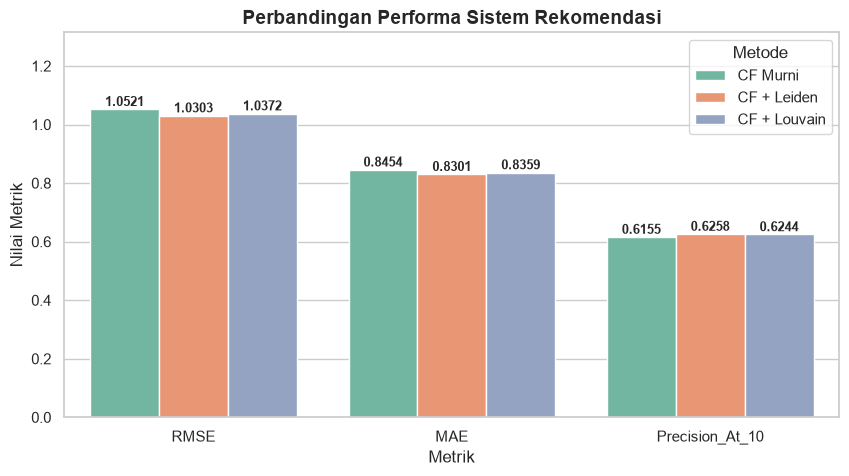

In [7]:
plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")

# Formatting data untuk plotting
df_melted = df_eval.melt(id_vars=["Metode"], value_vars=["RMSE", "MAE", "Precision_At_10"], 
                         var_name="Metrik", value_name="Skor")

ax = sns.barplot(data=df_melted, x="Metrik", y="Skor", hue="Metode", palette="Set2")
plt.title("Perbandingan Performa Sistem Rekomendasi", fontsize=14, fontweight='bold')
plt.ylabel("Nilai Metrik")
plt.ylim(0, max(df_melted["Skor"]) * 1.25)

# Label Angka di Atas Batang
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.4f}", 
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 5), 
                    textcoords='offset points', fontsize=9, fontweight='bold')

plt.savefig("grafik_evaluasi_rekomendasi.png", dpi=300, bbox_inches='tight')
plt.show()

RMSE (Tingkat Error Kuadrat): CF + Leiden (1.0303) memberikan skor RMSE paling kecil dibanding Louvain (1.0372) dan CF Murni (1.0521). Pendekatan berbasis komunitas Leiden berhasil meningkatkan akurasi prediksi rating (memperkecil error) dibanding CF Murni.

MAE (Rata-rata Kesalahan Mutlak):CF + Leiden (0.8301) juga unggul dengan nilai kesalahan rata-rata terendah dibanding Louvain (0.8359) dan CF Murni (0.8454). Tebakan rating dari metode CF + Leiden secara rata-rata paling mendekati rating asli user.

Ketepatan Rekomendasi (Precision@10): CF + Leiden juga mencatatkan presisi tertinggi (0.6258 atau 62.58%). Artinya, rata-rata lebih dari 6 dari 10 film yang direkomendasikan sistem terbukti benar-benar disukai oleh user (rating asli $\ge 4.0$).